# **Import And Pre-Processing**

In [ ]:
import numpy as np
import pandas as pd
import sklearn as sk
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn import tree
from sklearn.metrics import accuracy_score, confusion_matrix, r2_score
from sklearn.metrics import classification_report
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import svm
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

from sklearn.linear_model import LinearRegression

from sklearn.model_selection import StratifiedKFold,cross_val_score

from sklearn.ensemble import BaggingClassifier


In [ ]:
Pima_dataset = pd.read_csv('/content/diabetes.csv')

In [ ]:
print("Dataset shape:", Pima_dataset.shape)

print("\nOutcome distribution:")
print(Pima_dataset["Outcome"].value_counts())

print("\nMissing values:")
print(Pima_dataset.isnull().sum())

print("\nZero values in medical measurements:")
print(
    (Pima_dataset[
        ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    ] == 0).sum()
)

Dataset shape: (768, 9)

Outcome distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero values in medical measurements:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [ ]:
Pima_dataset.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [ ]:
X = Pima_dataset.drop(columns='Outcome', axis=1)
Y = Pima_dataset['Outcome']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.20, random_state = 0)

In [ ]:
# URL: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html
# Estimate mutual information for a discrete target variable.
# Mutual information (MI) between two random variables is a non-negative value, which measures the dependency between the variables.
# It is equal to zero if and only if two random variables are independent, and higher values mean higher dependency.
from sklearn.feature_selection import mutual_info_classif

mutual_info = mutual_info_classif(X_train, y_train, random_state = 0)
mutual_info


array([0.01555395, 0.11340361, 0.01509219, 0.01042158, 0.02731686,
       0.07740352, 0.        , 0.04601336])

In [ ]:
mutual_info = pd.Series(mutual_info)
mutual_info.index = X_train.columns
mutual_info.sort_values(ascending = False)

Glucose                     0.113404
BMI                         0.077404
Age                         0.046013
Insulin                     0.027317
Pregnancies                 0.015554
BloodPressure               0.015092
SkinThickness               0.010422
DiabetesPedigreeFunction    0.000000
dtype: float64

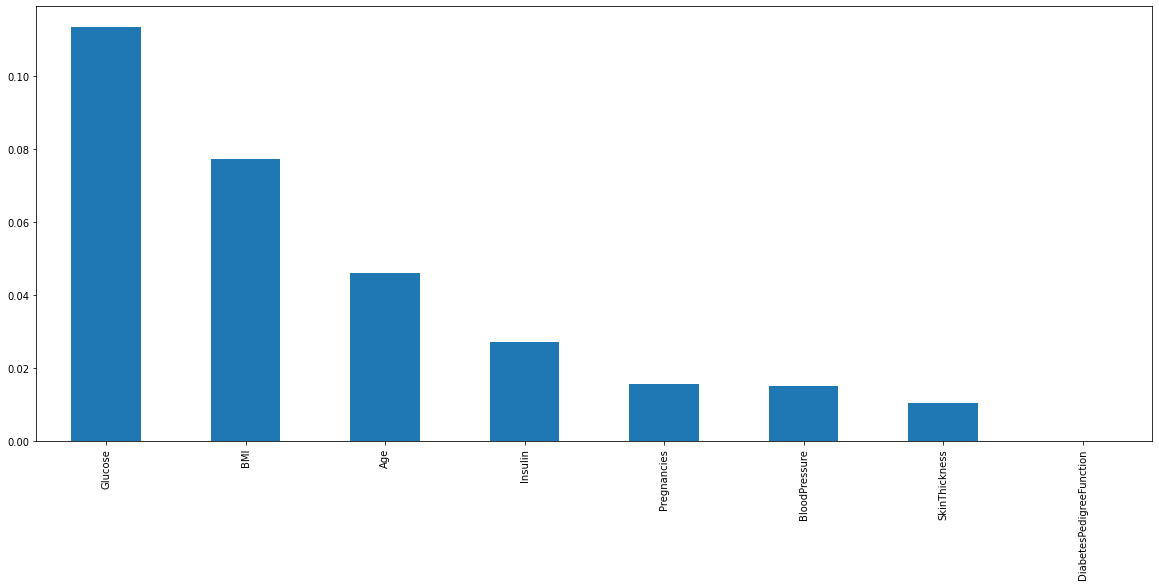

In [ ]:
plt.figure(figsize = (20, 8))
mutual_info.sort_values(ascending = False).plot.bar();

In [ ]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean', missing_values=0)
imputer = imputer.fit(Pima_dataset[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']])
Pima_dataset[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] = imputer.transform(Pima_dataset[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']])


In [ ]:
Pima_dataset['Outcome'].value_counts()

0    500
1    268
Name: Outcome, dtype: int64

In [ ]:
print("number of rows with glucose value 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['Glucose'] == 0])))
print("number of rows with missing BloodPressure 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['BloodPressure'] == 0])))
print("number of rows with missing skin thikness 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['SkinThickness'] == 0])))
print("number of rows with Insulin 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['Insulin'] == 0])))
print("number of rows with BMI 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['BMI'] == 0])))
print("number of rows with DiabetesPedigreeFunction 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['DiabetesPedigreeFunction'] == 0])))
print("number of rows with age 0 is: {0}".format(len(Pima_dataset.loc[Pima_dataset['Age'] == 0])))


number of rows with glucose value 0 is: 0
number of rows with missing BloodPressure 0 is: 0
number of rows with missing skin thikness 0 is: 0
number of rows with Insulin 0 is: 0
number of rows with BMI 0 is: 0
number of rows with DiabetesPedigreeFunction 0 is: 0
number of rows with age 0 is: 0


In [ ]:
Pima_dataset.drop(columns='DiabetesPedigreeFunction',axis=1, inplace=True)

In [ ]:
Pima_dataset.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Age,Outcome
0,6,148.0,72.000000,35.00000,155.548223,33.600000,50,1
1,1,85.0,66.000000,29.00000,155.548223,26.600000,31,0
2,8,183.0,64.000000,29.15342,155.548223,23.300000,32,1
3,1,89.0,66.000000,23.00000,94.000000,28.100000,21,0
4,0,137.0,40.000000,35.00000,168.000000,43.100000,33,1
5,5,116.0,74.000000,29.15342,155.548223,25.600000,30,0
6,3,78.0,50.000000,32.00000,88.000000,31.000000,26,1
7,10,115.0,72.405184,29.15342,155.548223,35.300000,29,0
8,2,197.0,70.000000,45.00000,543.000000,30.500000,53,1
9,8,125.0,96.000000,29.15342,155.548223,32.457464,54,1


In [ ]:
X = Pima_dataset.drop(columns='Insulin', axis=1)
Y = Pima_dataset['Insulin']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.20, random_state = 0)

In [ ]:
XGB = XGBRegressor(max_depth=10,learning_rate=0.1)
XGB.fit(X_train,y_train)

predictions_xgb = XGB.predict(X_test)


In [ ]:

#mean square error
final_mse = mean_squared_error(y_test, predictions_xgb)
#mean square error
final_rmse = np.sqrt(final_mse)
final_rmse

69.01115169843999

In [ ]:
RTML_dataset = pd.read_excel('/content/Diabetes dataset from RTML .xlsx')

In [ ]:
RTML_dataset.isna().sum()

Pregnancies        0
Glucose            0
BloodPressure      0
SkinThickness      0
Insulin          109
BMI                0
Age                0
Outcome            0
dtype: int64

In [ ]:
X1 = RTML_dataset.drop(columns='Insulin', axis=1)
Y1 = RTML_dataset['Insulin']

In [ ]:
Y1 = XGB.predict(X1)

In [ ]:
Y1.shape

(109,)

In [ ]:
Y2= pd.DataFrame(Y1)

In [ ]:
Y2.columns=['Insulin']

In [ ]:
Y2.head()

,Insulin
0,169.939316
1,156.359818
2,93.892448
3,109.821793
4,111.143501


In [ ]:
Y2.shape

(109, 1)

# **Merging The insulin column**

In [ ]:
RTML_dataset.columns
RTML_dataset.shape

(109, 8)

In [ ]:
RTML_dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Age,Outcome
0,5,88.2,106.0,4.8,NaN,14.794213,50,0
1,6,73.8,74.0,7.5,NaN,24.851410,50,0
2,1,86.4,87.0,18.4,NaN,41.621307,30,0
3,1,97.2,71.0,15.0,NaN,22.608427,28,0
4,5,90.0,96.0,7.6,NaN,19.154528,50,0


In [ ]:
RTML_dataset.drop(columns='Insulin',axis=1, inplace=True)

In [ ]:
RTML_dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,BMI,Age,Outcome
0,5,88.2,106.0,4.8,14.794213,50,0
1,6,73.8,74.0,7.5,24.851410,50,0
2,1,86.4,87.0,18.4,41.621307,30,0
3,1,97.2,71.0,15.0,22.608427,28,0
4,5,90.0,96.0,7.6,19.154528,50,0


In [ ]:
Y2.columns
Y2.shape

(109, 1)

In [ ]:
Y2.head()

,Insulin
0,169.939316
1,156.359818
2,93.892448
3,109.821793
4,111.143501


In [ ]:
Insulin_Merged = pd.concat([RTML_dataset, Y2], axis=1)


Insulin_Merged.columns



NameError: name 'RTML_dataset' is not defined

In [ ]:
Insulin_Merged.shape

(109, 8)

In [ ]:
Insulin_Merged.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,BMI,Age,Outcome,Insulin
0,5,88.2,106.0,4.8,14.794213,50,0,169.939316
1,6,73.8,74.0,7.5,24.851410,50,0,156.359818
2,1,86.4,87.0,18.4,41.621307,30,0,93.892448
3,1,97.2,71.0,15.0,22.608427,28,0,109.821793
4,5,90.0,96.0,7.6,19.154528,50,0,111.143501
5,0,70.2,83.0,6.7,23.051801,18,0,139.253876
6,3,84.6,74.0,4.2,14.130982,40,0,163.274994
7,3,95.4,84.0,15.0,39.700324,30,0,100.884689
8,0,88.2,74.0,4.5,16.567359,18,0,139.365509
9,0,79.2,67.0,12.5,21.518855,18,0,82.253777


# **Merge with PIMA DATASET**

In [ ]:
RTML_Merged = Insulin_Merged[["Pregnancies", "Glucose", "BloodPressure","SkinThickness","Insulin", "BMI", "Age","Outcome"]]

NameError: name 'Insulin_Merged' is not defined

In [ ]:
RTML_Merged.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Age,Outcome
0,5,88.2,106.0,4.8,169.939316,14.794213,50,0
1,6,73.8,74.0,7.5,156.359818,24.851410,50,0
2,1,86.4,87.0,18.4,93.892448,41.621307,30,0
3,1,97.2,71.0,15.0,109.821793,22.608427,28,0
4,5,90.0,96.0,7.6,111.143501,19.154528,50,0
5,0,70.2,83.0,6.7,139.253876,23.051801,18,0
6,3,84.6,74.0,4.2,163.274994,14.130982,40,0
7,3,95.4,84.0,15.0,100.884689,39.700324,30,0
8,0,88.2,74.0,4.5,139.365509,16.567359,18,0
9,0,79.2,67.0,12.5,82.253777,21.518855,18,0


In [ ]:
pieces = {"x": Pima_dataset, "y": RTML_Merged}

PIMA_RTML = pd.concat(pieces)

NameError: name 'RTML_Merged' is not defined

In [ ]:
PIMA_RTML.shape

(877, 8)

In [ ]:
PIMA_RTML.head(10)

Pregnancies  Glucose  BloodPressure  SkinThickness     Insulin  \
x 0            6    148.0      72.000000       35.00000  155.548223   
  1            1     85.0      66.000000       29.00000  155.548223   
  2            8    183.0      64.000000       29.15342  155.548223   
  3            1     89.0      66.000000       23.00000   94.000000   
  4            0    137.0      40.000000       35.00000  168.000000   
  5            5    116.0      74.000000       29.15342  155.548223   
  6            3     78.0      50.000000       32.00000   88.000000   
  7           10    115.0      72.405184       29.15342  155.548223   
  8            2    197.0      70.000000       45.00000  543.000000   
  9            8    125.0      96.000000       29.15342  155.548223   

           BMI  Age  Outcome  
x 0  33.600000   50        1  
  1  26.600000   31        0  
  2  23.300000   32        1  
  3  28.100000   21        0  
  4  43.100000   33        1  
  5  25.600000   30        0  
  6  31.000000   26        1  
  7  35.300000   29        0  
  8  30.500000   53        1  
  9  32.457464   54        1

# **Split the Data**

In [ ]:
X = PIMA_RTML.drop(columns='Outcome', axis=1)
Y = PIMA_RTML['Outcome']

NameError: name 'PIMA_RTML' is not defined

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


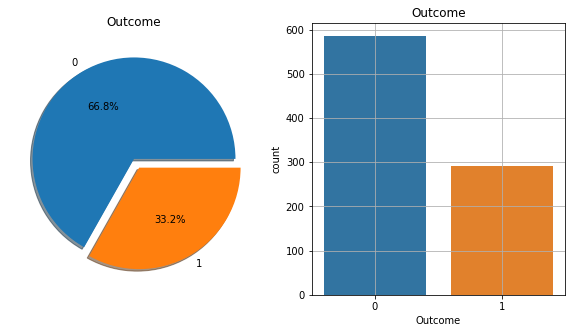

In [ ]:
f,ax = plt.subplots(1,2, figsize=(10,5))
PIMA_RTML['Outcome'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%', ax=ax[0],shadow=True)
ax[0].set_title('Outcome')
ax[0].set_ylabel('')
sns.countplot('Outcome', data=PIMA_RTML, ax=ax[1])
ax[1].set_title('Outcome')
N,P = PIMA_RTML['Outcome'].value_counts()

plt.grid()
plt.show()

In [ ]:
PIMA_RTML['Outcome'].value_counts()

0    586
1    291
Name: Outcome, dtype: int64

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.20, random_state = 0, stratify =Y)

In [ ]:
print(X.shape, X_train.shape,y_train.shape, X_test.shape)

(768, 8) (614, 8) (614,) (154, 8)


# **ADSYN Implementation**

In [ ]:
from imblearn.over_sampling import ADASYN
from collections import Counter

counter  = Counter(y_train)
print('Before',counter)
ada = ADASYN(random_state=0,sampling_strategy='minority')

X_smote, y_smote = ada.fit_resample(X_train, y_train)

counter = Counter(y_smote);
print('After',counter)


Before Counter({0: 393, 1: 221})
After Counter({1: 393, 0: 393})


In [ ]:

# Befor smote
y_train.value_counts()

0    468
1    233
Name: Outcome, dtype: int64

In [ ]:

# after smote

y_smote.value_counts()

0    468
1    423
Name: Outcome, dtype: int64

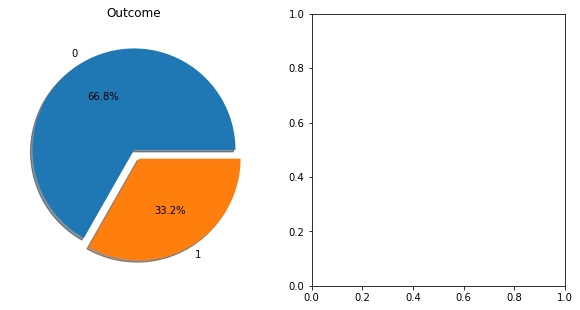

In [ ]:
# outcome before smote
f,ax = plt.subplots(1,2, figsize=(10,5))
y_train.value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%', ax=ax[0],shadow=True)
ax[0].set_title('Outcome')
ax[0].set_ylabel('')



plt.show()

**# After smote**

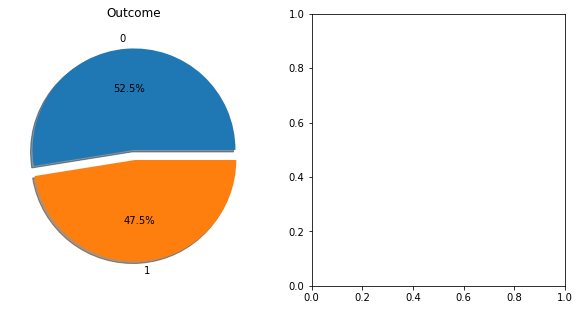

In [ ]:
# outcome
f,ax = plt.subplots(1,2, figsize=(10,5))
y_smote.value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%', ax=ax[0],shadow=True)
ax[0].set_title('Outcome')
ax[0].set_ylabel('')



plt.show()

In [ ]:

# Befor smote
y_train.value_counts()

0    468
1    233
Name: Outcome, dtype: int64

In [ ]:
# after smote

y_smote.value_counts()

0    468
1    423
Name: Outcome, dtype: int64

#  **Grid search on svm (PERFECTLY DONE)**



In [ ]:
# We need to scale correctly (We will use MinMax Scaler to do this)
cols_to_scale = ['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'Age']
scaler = MinMaxScaler()
scaler.fit(X_smote[cols_to_scale])
X_smote[cols_to_scale] = scaler.transform(X_smote[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [ ]:
svm_clf = svm.SVC()
# defining parameter range
param_grid = {'C': [0.1, 1, 10, 100, 1000],
              'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
              'kernel': ['rbf']}

svm_grid = GridSearchCV(SVC(), param_grid, refit = True, verbose = 3)

# fitting the model for grid search
svm_grid.fit(X_smote, y_smote)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.793 total time=   0.2s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.764 total time=   0.1s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.764 total time=   0.1s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.657 total time=   0.1s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.764 total time=   0.1s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.564 total time=   0.1s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.579 total time=   0.2s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.567 total time=   0.2s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.551 total time=   0.1s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.551 total time=   0.1s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.525 total time=   0.1s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100, 1000],
                         'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                         'kernel': ['rbf']},
             verbose=3)

In [ ]:
svm_grid.best_estimator_
svm_bestgrid=svm_grid.best_estimator_
svm_bestgrid

SVC(C=1, gamma=1)

In [ ]:
y_pred=svm_bestgrid.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))

[[88 30]
 [18 40]]
Accuracy Score 0.7272727272727273
              precision    recall  f1-score   support

           0       0.83      0.75      0.79       118
           1       0.57      0.69      0.62        58

    accuracy                           0.73       176
   macro avg       0.70      0.72      0.71       176
weighted avg       0.74      0.73      0.73       176



**K-fold cross validation(SVM)**

In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(svm_grid,X,Y,cv=skfold)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.667 total time=   0.1s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.664 total time=   0.0s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.671 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.671 total time=   0.0s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.671 total time=   0.1s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.667 total time=   0.1s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.664 total time=   0.1s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.671 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.671 total time=   0.1s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.671 total time=   0.1s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.667 total time=   0.1s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

In [ ]:
cv_score

array([0.75      , 0.67613636, 0.78857143, 0.78857143, 0.85714286])

In [ ]:
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7720844155844157 +/- 0.05911401146792515


# **Bagging Decision tree(PERFECTLY DONE)**


In [ ]:
bagging = BaggingClassifier(DecisionTreeClassifier(random_state=42),n_estimators=500,
                           max_samples=100,bootstrap=True,n_jobs=-1,random_state=42,
                           oob_score=True)
bagging.fit(X_smote,y_smote)

BaggingClassifier(base_estimator=DecisionTreeClassifier(random_state=42),
                  max_samples=100, n_estimators=500, n_jobs=-1, oob_score=True,
                  random_state=42)

In [ ]:
y_pred=bagging.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))

[[95 23]
 [14 44]]
Accuracy Score 0.7897727272727273
              precision    recall  f1-score   support

           0       0.87      0.81      0.84       118
           1       0.66      0.76      0.70        58

    accuracy                           0.79       176
   macro avg       0.76      0.78      0.77       176
weighted avg       0.80      0.79      0.79       176



**K-fold cross validation (Bagging)**

In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(bagging,X,Y,cv=skfold)

In [ ]:
cv_score

array([0.75      , 0.68181818, 0.78857143, 0.79428571, 0.88      ])

In [ ]:
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7789350649350648 +/- 0.06451596702899699


# **Decision Tree(Perfectly Done)**

Depth =  2 , Training Accuracy =  0.7384960718294051 , Test Accuracy =  0.7159090909090909 , Diff =  2.2586980920314192  %
Depth =  3 , Training Accuracy =  0.7631874298540965 , Test Accuracy =  0.8011363636363636 , Diff =  3.794893378226716  %
Depth =  4 , Training Accuracy =  0.8035914702581369 , Test Accuracy =  0.7954545454545454 , Diff =  0.8136924803591516  %
Depth =  5 , Training Accuracy =  0.8282828282828283 , Test Accuracy =  0.7840909090909091 , Diff =  4.419191919191922  %
Depth =  6 , Training Accuracy =  0.8417508417508418 , Test Accuracy =  0.7613636363636364 , Diff =  8.038720538720545  %
Depth =  7 , Training Accuracy =  0.8698092031425365 , Test Accuracy =  0.75 , Diff =  11.980920314253652  %
Depth =  8 , Training Accuracy =  0.8922558922558923 , Test Accuracy =  0.7272727272727273 , Diff =  16.498316498316502  %
Depth =  9 , Training Accuracy =  0.9169472502805837 , Test Accuracy =  0.6931818181818182 , Diff =  22.376543209876544  %
Depth =  10 , Training Accuracy =

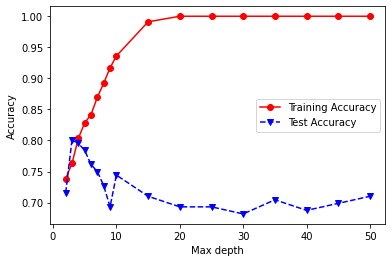

In [ ]:
maxdepths = [2,3,4,5,6,7,8,9,10,15,20,25,30,35,40,45,50]
trainAcc = np.zeros(len(maxdepths))
testAcc = np.zeros(len(maxdepths))

index = 0
for depth in maxdepths:
    clf = tree.DecisionTreeClassifier(max_depth=depth)
    clf = clf.fit(X_smote, y_smote)
    y_predTrain = clf.predict(X_smote)
    y_predTest = clf.predict(X_test)
    trainAcc[index] = accuracy_score(y_smote, y_predTrain)
    testAcc[index] = accuracy_score(y_test, y_predTest)
    print("Depth = ", depth, ", Training Accuracy = ", trainAcc[index], ", Test Accuracy = ", testAcc[index],
          ", Diff = ", np.abs((trainAcc[index]-testAcc[index])*100), " %")
    index += 1


#########################################
# Plot of training and test accuracies
#########################################

plt.plot(maxdepths,trainAcc,'ro-',maxdepths,testAcc,'bv--')
plt.legend(['Training Accuracy','Test Accuracy'])
plt.xlabel('Max depth')
plt.ylabel('Accuracy');

In [ ]:
# create a model
dt = DecisionTreeClassifier(max_depth = 2, random_state=0)
dt.fit(X_smote, y_smote)

DecisionTreeClassifier(max_depth=2, random_state=0)

In [ ]:
# Accuracy on Train
print("Training Accuracy is: ", dt.score(X_smote, y_smote))

# Accuracy on Test
print("Testing Accuracy is: ", dt.score(X_test, y_test))
X_test_prediction  = dt.predict(X_test)

print(classification_report(y_test, X_test_prediction))

Training Accuracy is:  0.72264631043257
Testing Accuracy is:  0.6428571428571429
              precision    recall  f1-score   support

           0       0.93      0.52      0.67       107
           1       0.46      0.91      0.61        47

    accuracy                           0.64       154
   macro avg       0.70      0.72      0.64       154
weighted avg       0.79      0.64      0.65       154



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(dt,X,Y,cv=skfold)


In [ ]:
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7370087428910959 +/- 0.012780871304303372


# **Logistic** **Regression(Perfectly Done)**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# Logistic Regression hyperparameter tuning
grid_params = [
    {
        'max_iter': [10000],
        'warm_start': [True, False],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear']
    },
    {
        'max_iter': [10000],
        'warm_start': [True, False],
        'penalty': ['elasticnet'],
        'solver': ['saga'],
        'l1_ratio': [0.5]
    },
    {
        'max_iter': [10000],
        'warm_start': [True, False],
        'penalty': [None],
        'solver': ['lbfgs']
    }
]

lr = LogisticRegression(random_state=42)

lr_grid = GridSearchCV(
    estimator=lr,
    param_grid=grid_params,
    verbose=1,
    scoring='accuracy',
    cv=3,
    n_jobs=-1,
    error_score='raise'
)

# Train using the original notebook's data
lr_grid.fit(X_smote, y_smote)

# Save best model for later cells
lr_bestgrid = lr_grid.best_estimator_

print("Logistic Regression completed successfully!")
print("Best parameters:", lr_grid.best_params_)
print("Best cross-validation accuracy:", lr_grid.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Logistic Regression completed successfully!
Best parameters: {'max_iter': 10000, 'penalty': 'l2', 'solver': 'liblinear', 'warm_start': True}
Best cross-validation accuracy: 0.712468193384224


In [ ]:
lr_bestgrid=lr_grid.best_estimator_

In [ ]:
y_pred=lr_bestgrid.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))

[[79 28]
 [ 8 39]]
Accuracy Score 0.7662337662337663
              precision    recall  f1-score   support

           0       0.91      0.74      0.81       107
           1       0.58      0.83      0.68        47

    accuracy                           0.77       154
   macro avg       0.75      0.78      0.75       154
weighted avg       0.81      0.77      0.77       154



**Logistic regression K fold**

In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(lr_bestgrid,X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7721925133689839 +/- 0.022368682173990264


# **Gausien Naive Bays(Perfectly Done)**

In [ ]:
nb_classifier = GaussianNB()

params_NB = {'var_smoothing': np.logspace(0,-9, num=100)}
gs_NB = GridSearchCV(GaussianNB(),
                 param_grid=params_NB,
                 cv=3,   # use any cross validation technique
                 verbose=1,
                 scoring='accuracy')
gs_NB.fit(X_smote, y_smote)


Fitting 3 folds for each of 100 candidates, totalling 300 fits


GridSearchCV(cv=3, estimator=GaussianNB(),
             param_grid={'var_smoothing': array([1.00000000e+00, 8.11130831e-01, 6.57933225e-01, 5.33669923e-01,
       4.32876128e-01, 3.51119173e-01, 2.84803587e-01, 2.31012970e-01,
       1.87381742e-01, 1.51991108e-01, 1.23284674e-01, 1.00000000e-01,
       8.11130831e-02, 6.57933225e-02, 5.33669923e-02, 4.32876128e-02,
       3.51119173e-02, 2.84803587e-02, 2.31...
       1.23284674e-07, 1.00000000e-07, 8.11130831e-08, 6.57933225e-08,
       5.33669923e-08, 4.32876128e-08, 3.51119173e-08, 2.84803587e-08,
       2.31012970e-08, 1.87381742e-08, 1.51991108e-08, 1.23284674e-08,
       1.00000000e-08, 8.11130831e-09, 6.57933225e-09, 5.33669923e-09,
       4.32876128e-09, 3.51119173e-09, 2.84803587e-09, 2.31012970e-09,
       1.87381742e-09, 1.51991108e-09, 1.23284674e-09, 1.00000000e-09])},
             scoring='accuracy', verbose=1)

In [ ]:
gs_NB.best_params_

{'var_smoothing': np.float64(5.336699231206313e-06)}

In [ ]:
gs_NB=gs_NB.best_estimator_

In [ ]:
y_pred=gs_NB.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))

[[84 23]
 [15 32]]
Accuracy Score 0.7532467532467533
              precision    recall  f1-score   support

           0       0.85      0.79      0.82       107
           1       0.58      0.68      0.63        47

    accuracy                           0.75       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.77      0.75      0.76       154



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(GaussianNB(),X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.762948051948052 +/- 0.059505518480507336



# **Random Forest(Perfectly Done)**

In [ ]:
###The hyperparameter we got from grid search
rf=RandomForestClassifier(max_depth=780, max_features='log2', n_estimators=600)
### fit the randomized model
rf.fit(X_smote, y_smote)


RandomForestClassifier(max_depth=780, max_features='log2', n_estimators=600)

In [ ]:
from sklearn.metrics import accuracy_score
y_pred=rf.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test, y_pred))

[[97 21]
 [21 37]]
Accuracy Score 0.7613636363636364
              precision    recall  f1-score   support

           0       0.82      0.82      0.82       118
           1       0.64      0.64      0.64        58

    accuracy                           0.76       176
   macro avg       0.73      0.73      0.73       176
weighted avg       0.76      0.76      0.76       176



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(rf,X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7789025974025974 +/- 0.045943549587432485


# **XG Boost(Perfectly Done)**

In [ ]:
###The hyperparameter we got from grid search
from xgboost import XGBClassifier
xgbc = XGBClassifier(colsample_bytree = 0.8,
 gamma= 1,
 max_depth= 3,
 min_child_weight= 1,
 subsample= 0.8,
 objective= 'binary:logistic',
 nthread= -1,
 scale_pos_weight=1).fit(X_smote, y_smote)

NameError: name 'X_smote' is not defined

In [ ]:

# COMP8240 - Pima-only XGBoost training demonstration
# This is a separate public-data reproduction.
# It does not recreate the original private RTML experiment.

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from imblearn.over_sampling import ADASYN
from xgboost import XGBClassifier

# 1. Load public Pima dataset
file_path = "/content/diabetes.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Upload diabetes.csv to Colab's Files panel first."
    )

df = pd.read_csv(file_path)

required_columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

if not set(required_columns).issubset(df.columns):
    raise ValueError(
        "This code requires the public Pima diabetes.csv "
        "with the eight features and Outcome column."
    )

X = df[required_columns[:-1]].copy()
y = df["Outcome"].astype(int)

# 2. Split BEFORE preprocessing and resampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Replace medically implausible zero values with missing
zero_missing_cols = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]

X_train = X_train.copy()
X_test = X_test.copy()

X_train[zero_missing_cols] = X_train[zero_missing_cols].replace(0, np.nan)
X_test[zero_missing_cols] = X_test[zero_missing_cols].replace(0, np.nan)

# Fit imputer ONLY on training data
imputer = SimpleImputer(strategy="median")

X_train_ready = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns
)

X_test_ready = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns
)

# 4. Create the missing resampled variables
adasyn = ADASYN(random_state=42, n_neighbors=5)

X_smote, y_smote = adasyn.fit_resample(
    X_train_ready, y_train
)

print("Training records before ADASYN:", len(X_train_ready))
print("Training records after ADASYN:", len(X_smote))
print("Testing records:", len(X_test_ready))

# 5. Train XGBoost using parameters from the original code
xgbc = XGBClassifier(
    colsample_bytree=0.8,
    gamma=1,
    max_depth=3,
    min_child_weight=1,
    subsample=0.8,
    objective="binary:logistic",
    nthread=-1,
    scale_pos_weight=1,
    eval_metric="logloss",
    random_state=42
)

xgbc.fit(X_smote, y_smote)

# 6. Evaluate on untouched test data
y_pred = xgbc.predict(X_test_ready)
y_prob = xgbc.predict_proba(X_test_ready)[:, 1]

print("\n=== PIMA-ONLY XGBOOST RESULTS ===")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nSUCCESS: XGBoost model trained and evaluated!")


Training records before ADASYN: 614
Training records after ADASYN: 793
Testing records: 154

=== PIMA-ONLY XGBOOST RESULTS ===
Accuracy: 0.7792
F1-score: 0.7018
ROC-AUC: 0.8131

Confusion Matrix:
[[80 20]
 [14 40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.80      0.82       100
           1       0.67      0.74      0.70        54

    accuracy                           0.78       154
   macro avg       0.76      0.77      0.76       154
weighted avg       0.79      0.78      0.78       154


SUCCESS: XGBoost model trained and evaluated!


In [ ]:
from sklearn.metrics import accuracy_score
y_pred=xgbc.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test, y_pred))

[[98 20]
 [15 43]]
Accuracy Score 0.8011363636363636
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       118
           1       0.68      0.74      0.71        58

    accuracy                           0.80       176
   macro avg       0.77      0.79      0.78       176
weighted avg       0.81      0.80      0.80       176



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(xgbc,X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7591545709192768 +/- 0.02469876789682416


In [ ]:
final_roc_auc = []

In [ ]:
probas1 = xgbc.predict_proba(X_test)[:, 1]

In [ ]:
false_positive_rate1, true_positive_rate1, threshold1 = roc_curve(y_test, probas1)

In [ ]:
print('roc_auc_score for XG Boost Classifier: ', roc_auc_score(y_test, probas1))

roc_auc_score for XG Boost Classifier:  0.8355537880294294


In [ ]:
final_roc_auc.append({'model_name': 'XG Boost Classifier', 'fpr': false_positive_rate1, 'tpr': true_positive_rate1, 'auc': roc_auc_score(y_test, probas1)})

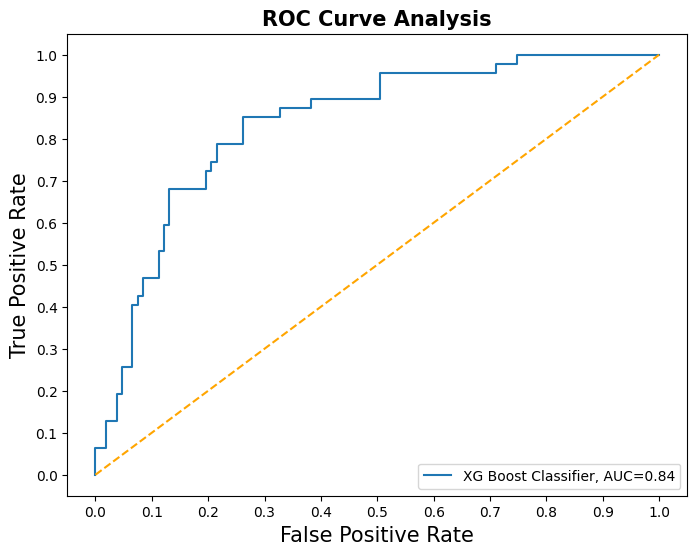

In [ ]:
fig = plt.figure(figsize=(8,6))

for m in final_roc_auc:
    plt.plot(m['fpr'],
             m['tpr'],
             label="{}, AUC={:.2f}".format(m['model_name'], m['auc']))

plt.plot([0,1], [0,1], color='orange', linestyle='--')

plt.xticks(np.arange(0.0, 1.1, step=0.1))
plt.xlabel("False Positive Rate", fontsize=15)

plt.yticks(np.arange(0.0, 1.1, step=0.1))
plt.ylabel("True Positive Rate", fontsize=15)

plt.title('ROC Curve Analysis', fontweight='bold', fontsize=15)
plt.legend(prop={'size':10}, loc='lower right')

plt.show()

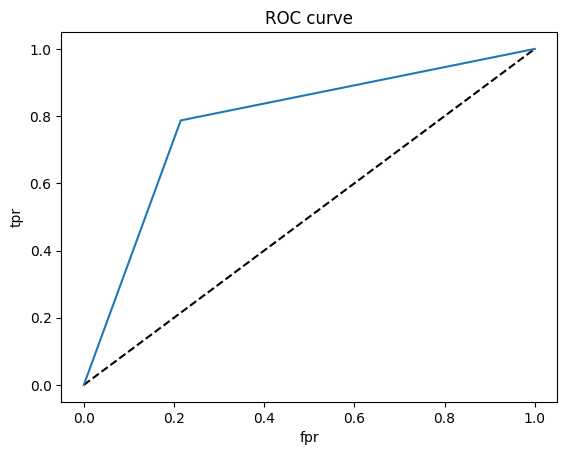

In [ ]:
from sklearn.metrics import roc_curve
y_pred = xgbc.predict(X_test)
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
plt.plot([0,1],[0,1],'k--')
plt.plot(fpr,tpr, label='XGBoost')
plt.xlabel('fpr')
plt.ylabel('tpr')
plt.title('ROC curve')
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_test,y_pred)

0.7859438924605494

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(confusion_matrix(y_test,y_pred))

[[98 20]
 [15 43]]


Text(0.5, 15.0, 'Predicted label')

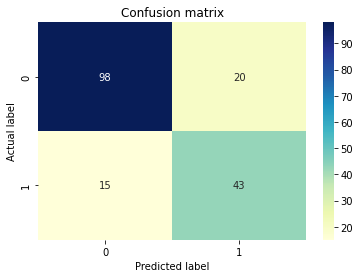

In [ ]:
p = sns.heatmap(pd.DataFrame(cm), annot=True, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

# **Ada Boost(Perfectly Done)**

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
#lrc = LogisticRegression(max_iter=1100)
abc = AdaBoostClassifier(n_estimators=50,base_estimator=rf,learning_rate=1).fit(X_smote, y_smote)

print(classification_report(y_test,abc.predict(X_test)))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82       118
           1       0.63      0.62      0.63        58

    accuracy                           0.76       176
   macro avg       0.72      0.72      0.72       176
weighted avg       0.75      0.76      0.76       176



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(abc,X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7823051948051949 +/- 0.04205903857182309


# **KNN(Perfectly Done)**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=74)
knn.fit(X_smote, y_smote)

# accuracy score on the test data
knn_prediction = knn.predict(X_test)
knn_prediction_accuracy = accuracy_score(knn_prediction, y_test)
print('Accuracy score of Test data: ', knn_prediction_accuracy)
print(classification_report(y_test, knn_prediction))

Accuracy score of Test data:  0.7272727272727273
              precision    recall  f1-score   support

           0       0.86      0.71      0.78       118
           1       0.56      0.76      0.65        58

    accuracy                           0.73       176
   macro avg       0.71      0.74      0.71       176
weighted avg       0.76      0.73      0.73       176



In [ ]:
k = range(1, 100)
train_acc = []
test_acc = []
for x in k:
    knn_clf = KNeighborsClassifier(n_neighbors = x) # Euclidean Distance Metric
    knn_clf.fit(X_smote, y_smote)
    y_pred = knn_clf.predict(X_test)
    train_acc.append(accuracy_score(y_smote, knn_clf.predict(X_smote)))
    test_acc.append(accuracy_score(y_test, y_pred))

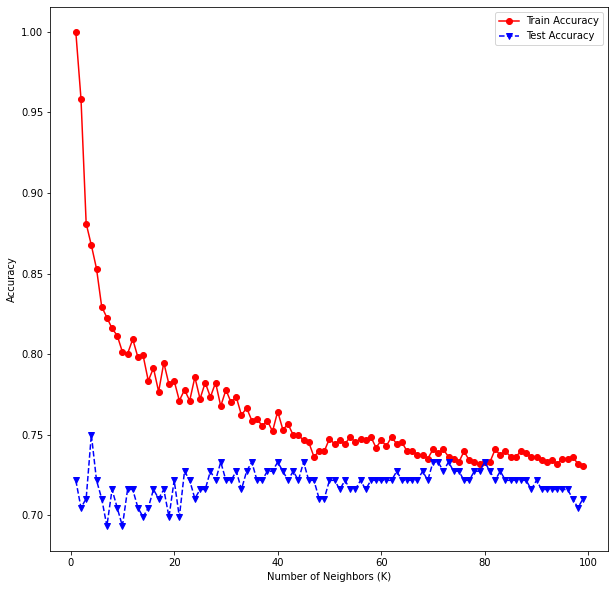

In [ ]:
plt.figure(figsize = (10,10))
plt.plot(k,train_acc,'ro-',k,test_acc,'bv--')
plt.legend(['Train Accuracy','Test Accuracy'])
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy');

In [ ]:
for x in k:
    print('Number of neighbors = ', x, "Train accuracy = ", train_acc[x-1], "Test Accuracy = ", test_acc[x-1], "Difference = ",
         (abs(train_acc[x-1] - test_acc[x-1])*100), "%")

Number of neighbors =  1 Train accuracy =  1.0 Test Accuracy =  0.7215909090909091 Difference =  27.840909090909093 %
Number of neighbors =  2 Train accuracy =  0.9584736251402918 Test Accuracy =  0.7045454545454546 Difference =  25.39281705948372 %
Number of neighbors =  3 Train accuracy =  0.8810325476992144 Test Accuracy =  0.7102272727272727 Difference =  17.080527497194165 %
Number of neighbors =  4 Train accuracy =  0.867564534231201 Test Accuracy =  0.75 Difference =  11.756453423120094 %
Number of neighbors =  5 Train accuracy =  0.8529741863075196 Test Accuracy =  0.7215909090909091 Difference =  13.138327721661058 %
Number of neighbors =  6 Train accuracy =  0.8294051627384961 Test Accuracy =  0.7102272727272727 Difference =  11.917789001122337 %
Number of neighbors =  7 Train accuracy =  0.8226711560044894 Test Accuracy =  0.6931818181818182 Difference =  12.948933782267114 %
Number of neighbors =  8 Train accuracy =  0.8159371492704826 Test Accuracy =  0.7159090909090909 Di

In [ ]:
knn = KNeighborsClassifier()
from sklearn.model_selection import GridSearchCV

grid_params = { 'n_neighbors' : [74],
               'weights' : ['uniform','distance'],
               'metric' : ['minkowski','euclidean','manhattan']}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    grid_params,
    verbose  = 1,
    cv = 10,
    return_train_score=False,
    scoring= 'accuracy',
    n_jobs = -1
    )

knn_grid.fit(X_smote, y_smote)


Fitting 10 folds for each of 6 candidates, totalling 60 fits


GridSearchCV(cv=10, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid={'metric': ['minkowski', 'euclidean', 'manhattan'],
                         'n_neighbors': [74],
                         'weights': ['uniform', 'distance']},
             scoring='accuracy', verbose=1)

In [ ]:
knn_grid.best_estimator_

KNeighborsClassifier(metric='manhattan', n_neighbors=74, weights='distance')

In [ ]:
knn_bestgrid=knn_grid.best_estimator_

In [ ]:
knn_bestgrid

KNeighborsClassifier(metric='manhattan', n_neighbors=74, weights='distance')

In [ ]:
y_pred=knn_bestgrid.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print("Accuracy Score {}".format(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))

[[82 36]
 [18 40]]
Accuracy Score 0.6931818181818182
              precision    recall  f1-score   support

           0       0.82      0.69      0.75       118
           1       0.53      0.69      0.60        58

    accuracy                           0.69       176
   macro avg       0.67      0.69      0.67       176
weighted avg       0.72      0.69      0.70       176



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(knn_bestgrid,X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7869090909090909 +/- 0.06714104345813365


# **Soft Voting**

In [ ]:
from sklearn.ensemble import VotingClassifier
estimator = []
estimator.append(('RF',RandomForestClassifier(max_depth=780, max_features='log2', n_estimators=600)))
estimator.append(('SVC', SVC(C=100, gamma=0.1,probability=True)))
estimator.append(('ABC',AdaBoostClassifier(n_estimators=50,base_estimator=rf,learning_rate=1)))
estimator.append(('Bag',BaggingClassifier(DecisionTreeClassifier(random_state=42),n_estimators=500,
                           max_samples=100,bootstrap=True,n_jobs=-1,random_state=42,
                           oob_score=True)))



# Voting Classifier with soft voting
Hyper_vot_soft = VotingClassifier(estimators = estimator, voting ='soft')
Hyper_vot_soft.fit(X_smote, y_smote)
y_pred = Hyper_vot_soft.predict(X_test)

# using accuracy_score metric to predict accuracy
score = accuracy_score(y_test, y_pred)
print("Soft Voting Score % d" % score)
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Soft Voting Score  0
[[95 23]
 [18 40]]
              precision    recall  f1-score   support

           0       0.84      0.81      0.82       118
           1       0.63      0.69      0.66        58

    accuracy                           0.77       176
   macro avg       0.74      0.75      0.74       176
weighted avg       0.77      0.77      0.77       176



In [ ]:
skfold = StratifiedKFold(n_splits=5)

cv_score = cross_val_score(Hyper_vot_soft,X,Y,cv=skfold)
results=cv_score
print("Results = ", np.mean(results),"+/-",np.std(results))

Results =  0.7800259740259741 +/- 0.04390587380709687


## **ZeroR**


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
dummy_clf = DummyClassifier(strategy = 'most_frequent', random_state = 20)
dummy_clf.fit(X_smote, y_smote)
y_pred = dummy_clf.predict(X_test)
print(classification_report(y_test, y_pred))
print("Train Accuracy: ", accuracy_score(y_smote, dummy_clf.predict(X_smote)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      1.00      0.82       107
           1       0.00      0.00      0.00        47

    accuracy                           0.69       154
   macro avg       0.35      0.50      0.41       154
weighted avg       0.48      0.69      0.57       154

Train Accuracy:  0.5
Test Accuracy:  0.6948051948051948


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
y_pred = dummy_clf.predict(X_test)

# Plotting Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm/cm.sum(axis=1)[:, np.newaxis]

## **Auc Curve**

In [ ]:
DTC2=BaggingClassifier(DecisionTreeClassifier(random_state=42),n_estimators=500,
                           max_samples=100,bootstrap=True,n_jobs=-1,random_state=42,
                           oob_score=True)
DTC2.fit(X_smote, y_smote)


DTC3=DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, random_state=0)
DTC3.fit(X_smote, y_smote)

rf_randomcv2= RandomForestClassifier(max_depth=780, max_features='log2', n_estimators=600)
rf_randomcv2.fit(X_smote, y_smote)

SVC2=SVC(C=100, gamma=0.1,probability=True)
SVC2.fit(X_smote, y_smote)

lr_grid2= lr_bestgrid
lr_grid2.fit(X_smote, y_smote)

gs_NB2=gs_NB
gs_NB2.fit(X_smote, y_smote)

XGB_clf2=XGBClassifier(colsample_bytree = 0.8,
 gamma= 1,
 max_depth= 3,
 min_child_weight= 1,
 subsample= 0.8,
 objective= 'binary:logistic',
 nthread= -1,
 scale_pos_weight=1)
XGB_clf2.fit(X_smote, y_smote)

knn_grid2= KNeighborsClassifier(n_neighbors=95,metric='manhattan', weights='distance')
knn_grid2.fit(X_smote, y_smote)


NameError: name 'BaggingClassifier' is not defined

In [ ]:
final_roc_auc = []

In [ ]:
# ROC-AUC probability predictions for available models

import numpy as np

models = {
    "Dummy": "dummy_clf",
    "Decision Tree": "DTC2",
    "KNN": "knn_grid2",
    "SVM": "SVC2",
    "Random Forest": "rf_randomcv2",
    "Naive Bayes": "gs_NB2",
    "AdaBoost": "abc",
    "XGBoost": "XGB_clf2",
    "Logistic Regression": "lr_grid2",
    "Soft Voting": "Hyper_vot_soft",
    "Decision Tree 2": "DTC3"
}

probabilities = {}

for model_name, variable_name in models.items():
    model = globals().get(variable_name)

    if model is None:
        print(f"SKIPPED: {model_name} ({variable_name} not defined)")
        continue

    try:
        probabilities[model_name] = model.predict_proba(X_test)[:, 1]
        print(f"SUCCESS: {model_name}")
    except (AttributeError, ValueError, TypeError) as e:
        print(f"SKIPPED: {model_name} - {e}")

# Keep original probability variable names for later notebook cells
probas1 = probabilities.get("Dummy")
probas2 = probabilities.get("Decision Tree")
probas3 = probabilities.get("KNN")
probas4 = probabilities.get("SVM")
probas5 = probabilities.get("Random Forest")
probas6 = probabilities.get("Naive Bayes")
probas7 = probabilities.get("AdaBoost")
probas8 = probabilities.get("XGBoost")
probas9 = probabilities.get("Logistic Regression")
probas10 = probabilities.get("Soft Voting")
probas11 = probabilities.get("Decision Tree 2")

print("\nAvailable models:", len(probabilities), "out of 11")

SUCCESS: Dummy
SUCCESS: Decision Tree
SUCCESS: KNN
SUCCESS: SVM
SUCCESS: Random Forest
SUCCESS: Naive Bayes
SKIPPED: AdaBoost (abc not defined)
SUCCESS: XGBoost
SUCCESS: Logistic Regression
SKIPPED: Soft Voting (Hyper_vot_soft not defined)
SUCCESS: Decision Tree 2

Available models: 9 out of 11


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curves only for available model predictions
# This uses the 'probabilities' dictionary from our previous cell.

roc_results = {}

for model_name, y_prob in probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    roc_results[model_name] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "auc": auc_score
    }

    print(f"{model_name}: AUC = {auc_score:.4f}")

# Preserve original variable names for later notebook cells
# Missing models will have None instead of causing an error.

model_order = [
    "Dummy",
    "Decision Tree",
    "KNN",
    "SVM",
    "Random Forest",
    "Naive Bayes",
    "AdaBoost",
    "XGBoost",
    "Logistic Regression",
    "Soft Voting",
    "Decision Tree 2"
]

for i, model_name in enumerate(model_order, start=1):
    result = roc_results.get(model_name)

    globals()[f"false_positive_rate{i}"] = (
        result["fpr"] if result else None
    )

    globals()[f"true_positive_rate{i}"] = (
        result["tpr"] if result else None
    )

    globals()[f"threshold{i}"] = (
        result["thresholds"] if result else None
    )

print("\nROC calculations completed!")
print("Models evaluated:", len(roc_results))

Dummy: AUC = 0.5000
Decision Tree: AUC = 0.8505
KNN: AUC = 0.8630
SVM: AUC = 0.6101
Random Forest: AUC = 0.8409
Naive Bayes: AUC = 0.8389
XGBoost: AUC = 0.8356
Logistic Regression: AUC = 0.8658
Decision Tree 2: AUC = 0.7210

ROC calculations completed!
Models evaluated: 9


In [ ]:
from sklearn.metrics import roc_auc_score
import pandas as pd

# Model names and probability variables from the original notebook
model_probabilities = {
    "ZeroR Classifier": probas1,
    "Bagging DecisionTree": probas2,
    "KNN Classifier": probas3,
    "SVM Classifier": probas4,
    "Random Forest Classifier": probas5,
    "Naive Bayes Classifier": probas6,
    "AdaBoost Classifier": probas7,
    "XGBoost Classifier": probas8,
    "Logistic Regression": probas9,
    "Voting Classifier": probas10,
    "DecisionTree": probas11
}

results = []

print("=== ROC-AUC SCORES ===\n")

for model_name, y_prob in model_probabilities.items():

    if y_prob is None:
        print(f"{model_name}: SKIPPED (model unavailable)")
        continue

    try:
        auc_score = roc_auc_score(y_test, y_prob)

        print(f"{model_name}: {auc_score:.4f}")

        results.append({
            "Model": model_name,
            "ROC-AUC": round(auc_score, 4)
        })

    except (ValueError, TypeError) as e:
        print(f"{model_name}: SKIPPED ({e})")

# Create a comparison table
auc_results = pd.DataFrame(results)

if not auc_results.empty:
    auc_results = auc_results.sort_values(
        by="ROC-AUC",
        ascending=False
    )

    print("\n=== MODEL COMPARISON TABLE ===")
    display(auc_results)
else:
    print("\nNo valid ROC-AUC scores were calculated.")

=== ROC-AUC SCORES ===

ZeroR Classifier: 0.5000
Bagging DecisionTree: 0.8505
KNN Classifier: 0.8630
SVM Classifier: 0.6101
Random Forest Classifier: 0.8409
Naive Bayes Classifier: 0.8389
AdaBoost Classifier: SKIPPED (model unavailable)
XGBoost Classifier: 0.8356
Logistic Regression: 0.8658
Voting Classifier: SKIPPED (model unavailable)
DecisionTree: 0.7210

=== MODEL COMPARISON TABLE ===


,Model,ROC-AUC
7,Logistic Regression,0.8658
2,KNN Classifier,0.8630
1,Bagging DecisionTree,0.8505
4,Random Forest Classifier,0.8409
5,Naive Bayes Classifier,0.8389
6,XGBoost Classifier,0.8356
8,DecisionTree,0.7210
3,SVM Classifier,0.6101
0,ZeroR Classifier,0.5000


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Reset the list to prevent duplicate results
final_roc_auc = []

# Original model names and probability predictions
model_probabilities = {
    "ZeroR Classifier": probas1,
    "Bagging Decision Tree Classifier": probas2,
    "KNeighbors Classifier": probas3,
    "SVM Classifier": probas4,
    "Random Forest Classifier": probas5,
    "Naive Bayes Classifier": probas6,
    "Ada Boost Classifier": probas7,
    "XG Boost Classifier": probas8,
    "Logistic Regression": probas9,
    "Voting Classifier": probas10,
    "Decision Tree Classifier": probas11
}

# Calculate ROC data for available models
for model_name, y_prob in model_probabilities.items():

    if y_prob is None:
        print(f"SKIPPED: {model_name} (model unavailable)")
        continue

    try:
        fpr, tpr, thresholds = roc_curve(y_test, y_prob)
        auc_score = roc_auc_score(y_test, y_prob)

        final_roc_auc.append({
            "model_name": model_name,
            "fpr": fpr,
            "tpr": tpr,
            "auc": auc_score
        })

        print(f"SUCCESS: {model_name} | AUC = {auc_score:.4f}")

    except (ValueError, TypeError) as e:
        print(f"SKIPPED: {model_name} | Error: {e}")

print("\nROC-AUC calculation completed!")
print("Total models evaluated:", len(final_roc_auc))

SUCCESS: ZeroR Classifier | AUC = 0.5000
SUCCESS: Bagging Decision Tree Classifier | AUC = 0.8505
SUCCESS: KNeighbors Classifier | AUC = 0.8630
SUCCESS: SVM Classifier | AUC = 0.6101
SUCCESS: Random Forest Classifier | AUC = 0.8409
SUCCESS: Naive Bayes Classifier | AUC = 0.8389
SKIPPED: Ada Boost Classifier (model unavailable)
SUCCESS: XG Boost Classifier | AUC = 0.8356
SUCCESS: Logistic Regression | AUC = 0.8658
SKIPPED: Voting Classifier (model unavailable)
SUCCESS: Decision Tree Classifier | AUC = 0.7210

ROC-AUC calculation completed!
Total models evaluated: 9


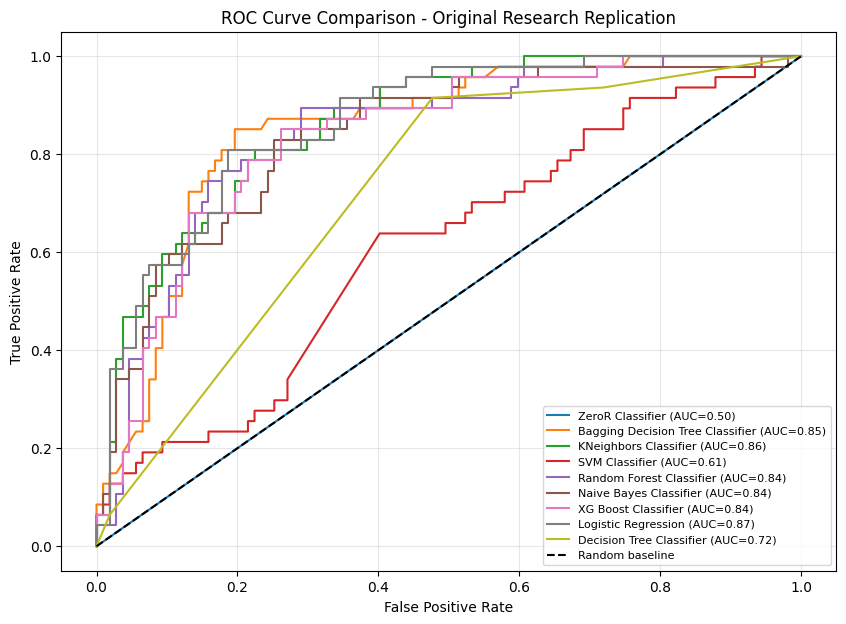

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model in final_roc_auc:
    plt.plot(
        model["fpr"],
        model["tpr"],
        label=f'{model["model_name"]} (AUC={model["auc"]:.2f})'
    )

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Original Research Replication")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import pandas as pd

Pima_dataset = pd.read_csv("/content/diabetes.csv")

print("Dataset restored successfully!")
print("Shape:", Pima_dataset.shape)
print("Columns:", Pima_dataset.columns.tolist())

display(Pima_dataset.head())

Dataset restored successfully!
Shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


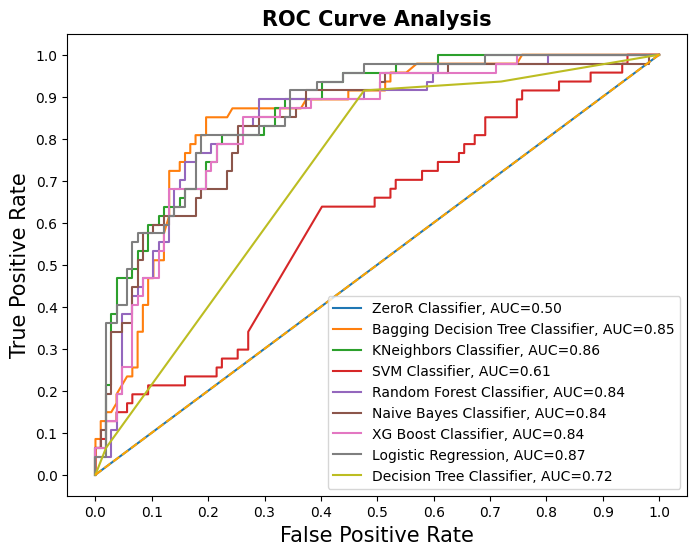

In [ ]:
fig = plt.figure(figsize=(8,6))

for m in final_roc_auc:
    plt.plot(m['fpr'],
             m['tpr'],
             label="{}, AUC={:.2f}".format(m['model_name'], m['auc']))

plt.plot([0,1], [0,1], color='orange', linestyle='--')

plt.xticks(np.arange(0.0, 1.1, step=0.1))
plt.xlabel("False Positive Rate", fontsize=15)

plt.yticks(np.arange(0.0, 1.1, step=0.1))
plt.ylabel("True Positive Rate", fontsize=15)

plt.title('ROC Curve Analysis', fontweight='bold', fontsize=15)
plt.legend(prop={'size':10}, loc='lower right')

plt.show()

In [ ]:
# export the figure.
fig.savefig('multiple_roc_curves.png')

In [2]:

import pandas as pd

Pima_dataset = pd.read_csv('/content/diabetes.csv')

print("Dataset shape:", Pima_dataset.shape)
print(Pima_dataset.head())


Dataset shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [3]:

import pandas as pd

rtml = pd.read_excel('/content/RTML without Insulin.xlsx')

print("RTML shape:", rtml.shape)
print("Columns:", rtml.columns.tolist())
print(rtml.head())


RTML shape: (109, 8)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'Age', 'Outcome']
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin        BMI  \
0            5     88.2          106.0            4.8      NaN  14.794213   
1            6     73.8           74.0            7.5      NaN  24.851410   
2            1     86.4           87.0           18.4      NaN  41.621307   
3            1     97.2           71.0           15.0      NaN  22.608427   
4            5     90.0           96.0            7.6      NaN  19.154528   

   Age  Outcome  
0   50        0  
1   50        0  
2   30        0  
3   28        0  
4   50        0  


In [4]:

print("RTML missing values:")
print(rtml.isnull().sum())

print("\nRTML duplicate rows:")
print(rtml.duplicated().sum())

print("\nRTML class distribution:")
print(rtml["Outcome"].value_counts())

print("\nRTML data types:")
print(rtml.dtypes)


RTML missing values:
Pregnancies        0
Glucose            0
BloodPressure      0
SkinThickness      0
Insulin          109
BMI                0
Age                0
Outcome            0
dtype: int64

RTML duplicate rows:
0

RTML class distribution:
Outcome
0    86
1    23
Name: count, dtype: int64

RTML data types:
Pregnancies        int64
Glucose          float64
BloodPressure    float64
SkinThickness    float64
Insulin          float64
BMI              float64
Age                int64
Outcome            int64
dtype: object


In [5]:

print("Pima insulin summary:")
print(Pima_dataset["Insulin"].describe())

print("\nPima insulin zero values:")
print((Pima_dataset["Insulin"] == 0).sum())

print("\nRTML insulin missing values:")
print(rtml["Insulin"].isna().sum())


Pima insulin summary:
count    768.000000
mean      79.799479
std      115.244002
min        0.000000
25%        0.000000
50%       30.500000
75%      127.250000
max      846.000000
Name: Insulin, dtype: float64

Pima insulin zero values:
374

RTML insulin missing values:
109


In [6]:

print("Pima shape:", Pima_dataset.shape)
print("RTML shape:", rtml.shape)

print("\nPima columns:")
print(Pima_dataset.columns.tolist())

print("\nRTML columns:")
print(rtml.columns.tolist())

print("\nShared columns:")
print(sorted(set(Pima_dataset.columns) & set(rtml.columns)))


Pima shape: (768, 9)
RTML shape: (109, 8)

Pima columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

RTML columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'Age', 'Outcome']

Shared columns:
['Age', 'BMI', 'BloodPressure', 'Glucose', 'Insulin', 'Outcome', 'Pregnancies', 'SkinThickness']


In [7]:

from sklearn.impute import SimpleImputer

# Keep the original datasets unchanged
pima_rep = Pima_dataset.copy()
rtml_rep = rtml.copy()

# Align the columns
pima_rep = pima_rep.drop(
    columns=["DiabetesPedigreeFunction"]
)

# Identify Pima medical measurements
medical_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Treat zero measurements as missing
pima_rep[medical_cols] = (
    pima_rep[medical_cols].replace(0, float("nan"))
)

# Apply the original-style mean imputation
imputer = SimpleImputer(strategy="mean")
pima_rep[medical_cols] = imputer.fit_transform(
    pima_rep[medical_cols]
)

print("Prepared Pima shape:", pima_rep.shape)
print("\nMissing values after preparation:")
print(pima_rep.isna().sum())
print("\nMean insulin:", round(pima_rep["Insulin"].mean(), 2))


Prepared Pima shape: (768, 8)

Missing values after preparation:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Age              0
Outcome          0
dtype: int64

Mean insulin: 155.55


In [8]:

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

# Input features for insulin prediction
features = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "BMI", "Age"
]

X = pima_rep[features]
y = pima_rep["Insulin"]

# Hold out some Pima records to check prediction error
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train insulin prediction model
insulin_model = XGBRegressor(
    max_depth=10,
    learning_rate=0.1,
    n_estimators=100,
    objective="reg:squarederror",
    random_state=42
)

insulin_model.fit(X_train, y_train)

# Evaluate on held-out Pima records
test_predictions = insulin_model.predict(X_test)

print("Insulin prediction MAE:",
      round(mean_absolute_error(y_test, test_predictions), 2))

# Train on all prepared Pima records before RTML prediction
insulin_model.fit(X, y)

# Estimate the missing RTML insulin measurements
rtml_rep["Insulin"] = insulin_model.predict(
    rtml_rep[features]
)

print("\nRTML shape:", rtml_rep.shape)
print("Missing insulin values:",
      rtml_rep["Insulin"].isna().sum())
print("Predicted insulin summary:")
print(rtml_rep["Insulin"].describe())


Insulin prediction MAE: 43.8

RTML shape: (109, 8)
Missing insulin values: 0
Predicted insulin summary:
count    109.000000
mean     136.789688
std       50.675297
min       43.864151
25%      104.902451
50%      124.243423
75%      159.981735
max      298.197601
Name: Insulin, dtype: float64


In [9]:

# Combine prepared Pima and RTML datasets
combined_rep = pd.concat(
    [pima_rep, rtml_rep],
    ignore_index=True
)

print("Combined dataset shape:", combined_rep.shape)

print("\nMissing values:")
print(combined_rep.isna().sum())

print("\nClass distribution:")
print(combined_rep["Outcome"].value_counts())

print("\nDuplicate rows:")
print(combined_rep.duplicated().sum())

print("\nFirst five records:")
print(combined_rep.head())


Combined dataset shape: (877, 8)

Missing values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Age              0
Outcome          0
dtype: int64

Class distribution:
Outcome
0    586
1    291
Name: count, dtype: int64

Duplicate rows:
0

First five records:
   Pregnancies  Glucose  BloodPressure  SkinThickness     Insulin   BMI  Age  \
0            6    148.0           72.0       35.00000  155.548223  33.6   50   
1            1     85.0           66.0       29.00000  155.548223  26.6   31   
2            8    183.0           64.0       29.15342  155.548223  23.3   32   
3            1     89.0           66.0       23.00000   94.000000  28.1   21   
4            0    137.0           40.0       35.00000  168.000000  43.1   33   

   Outcome  
0        1  
1        0  
2        1  
3        0  
4        1  


In [10]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from imblearn.over_sampling import ADASYN
from xgboost import XGBClassifier

# Separate input features and target
X = combined_rep.drop(columns=["Outcome"])
y = combined_rep["Outcome"]

# Create an 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Apply ADASYN only to the training data
adasyn = ADASYN(random_state=0)
X_train_balanced, y_train_balanced = adasyn.fit_resample(
    X_train, y_train
)

# Train XGBoost
model_rep = XGBClassifier(
    random_state=0,
    eval_metric="logloss"
)
model_rep.fit(X_train_balanced, y_train_balanced)

# Evaluate on untouched test data
y_pred = model_rep.predict(X_test)
y_prob = model_rep.predict_proba(X_test)[:, 1]

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Balanced training records:", len(X_train_balanced))

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))


Training records: 701
Test records: 176
Balanced training records: 894

Accuracy: 0.7443
F1-score: 0.6087
ROC-AUC: 0.7949

Confusion matrix:
[[96 22]
 [23 35]]

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       118
           1       0.61      0.60      0.61        58

    accuracy                           0.74       176
   macro avg       0.71      0.71      0.71       176
weighted avg       0.74      0.74      0.74       176



In [11]:

import xgboost
import sklearn
import imblearn

print("XGBoost version:", xgboost.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Imbalanced-learn version:", imblearn.__version__)

print("\nXGBoost parameters:")
print(model_rep.get_params())

print("\nTraining class counts before ADASYN:")
print(y_train.value_counts())

print("\nTraining class counts after ADASYN:")
print(y_train_balanced.value_counts())


XGBoost version: 3.4.1
Scikit-learn version: 1.6.1
Imbalanced-learn version: 0.14.2

XGBoost parameters:
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 0, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_paramet

In [12]:

import json

replication_summary = {
    "experiment": "Pima + RTML, XGBoost + ADASYN",
    "dataset_rows": 877,
    "train_rows": 701,
    "test_rows": 176,
    "adasyn_train_rows": 894,
    "accuracy": 0.7443,
    "f1_score": 0.6087,
    "roc_auc": 0.7949,
    "xgboost_version": "3.4.1",
    "sklearn_version": "1.6.1",
    "imblearn_version": "0.14.2",
    "random_state": 0,
    "limitations": [
        "Original-style preprocessing before classification split",
        "Insulin values estimated using XGBoost regression",
        "Exact equivalence to authors' implementation not established"
    ]
}

with open(
    "/content/COMP8240_replication_summary.json", "w"
) as f:
    json.dump(replication_summary, f, indent=2)

print("Replication summary saved successfully.")


Replication summary saved successfully.
